# Benchmark: accuracy and recovered structure against EBM, APLR, tree boosting and mgcv

This study compares mboostrs with seven other methods on two questions: how
well each predicts, and how much of the structure that generated the data an
analyst can read back from the fitted model. [](library_comparison.ipynb)
answers the first question on real data; this page adds the second, which
needs data whose structure is known, so most of the evidence comes from
simulations with a known truth, and four real data sets carry the accuracy,
speed and stability comparison.

The methods are:

| Method | What it fits | Tuning | Where its insight comes from |
|---|---|---|---|
| mboostrs `gamboost` | component-wise boosting of P-splines, one `bbs` per feature | `mstop` by 5-fold CV | each learner's contribution (`predict(which=)`) |
| mboostrs + deselection | the same, then learners below 1% of the risk reduction dropped and refitted (`mb.deselect`) | CV again after the drop | as above |
| mboostrs + probing | terms selected before the first permuted shadow (a copy of a feature with its values shuffled, used as a noise reference), refitted (`mb.probe`) | CV for the refit | as above |
| mboostrs autospec | `autospec(budget=400, interactions="adopt")`, the package's one-call route | its own probes | as above |
| mboostrs + REML refit | deselection, then the kept terms refitted as one penalized GAM with REML smoothing (restricted maximum likelihood, `mb.gam_refit`) | REML | the refit's terms and their Bayesian intervals |
| EBM (interpret) | cyclic boosting of binned shape functions, bagged; adds pair terms by default | internal early stopping | its term scores and bag standard deviations |
| EBM additive | EBM with `interactions=0` | as above | as above |
| APLR | boosting of piecewise-linear terms; allows pairs by default | internal CV | its per-term contributions |
| APLR additive | APLR with `max_interaction_level=0` | as above | as above |
| XGBoost, LightGBM, CatBoost | gradient-boosted trees (depth-wise, leaf-wise histogram, ordered boosting) | tree size and rounds on a 20% validation split | TreeSHAP values (per-row Shapley-style attributions for tree models) |
| mgcv (R) | penalized-likelihood GAM, `s()` per feature, REML, double penalty `select=TRUE` | REML | term predictions and their standard errors |

Every method runs single-threaded, and every reported time includes the
method's own tuning. The harness is `benches/bench_insights.py`; it stores
every seed and split, and the figures below are computed from that file.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | how well each method predicts, and how much of the known structure (effect shapes, relevant features, a pairwise interaction, a conditional standard deviation) can be read back from its fit |
| **Observed response** | a simulated continuous or 0/1 response in four tasks; the target column of four real data sets |
| **Estimand** | held-out excess squared error, AUC and log score; the error of each recovered effect shape against the true one; the share of true effects inside a nominal 90% interval |
| **Units** | squared error in the response's units; shape error per unit of the true effect's standard deviation |
| **Sampling unit** | one simulated row; one row of each real data set |
| **Dependence** | independent rows by construction in the simulations; treated as independent in the real data |
| **Split / resampling unit** | one fixed 5,000-row simulated test set with 10 training seeds; 5 random 75/25 splits of each real data set |
| **Tuning** | each method's own validation: 5-fold CV of mstop for mboostrs, a 20% validation split for the tree libraries, REML for mgcv, internal stopping for EBM and APLR |
| **Uncertainty** | standard error over seeds or splits |
| **Claim type** | predictive and methodological: properties of the estimators on data whose truth the simulation sets |
:::

In [1]:
import json
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl

bench = json.loads(Path("bench_insights.json").read_text())
results = pl.DataFrame([r for r in bench["results"] if "error" not in r],
                       infer_schema_length=None)
failed = [r for r in bench["results"] if "error" in r]
protocol = bench["protocol"]
versions = bench["versions"]
(f"{results.height} result rows, {len(failed)} failed fits; "
 f"{protocol['seeds']} seeds, {protocol['splits']} splits per real data set")

'610 result rows, 0 failed fits; 10 seeds, 5 splits per real data set'

In [2]:
def summarise(frame, metrics, by="method"):
    # Mean and standard error over seeds (or splits) for each metric.
    parts = []
    for metric in metrics:
        parts += [pl.col(metric).mean().alias(metric),
                  (pl.col(metric).std() / pl.col(metric).count().sqrt()).alias(f"{metric} se")]
    return frame.group_by(by).agg(parts)


def rounded(frame, digits=3):
    return frame.with_columns(pl.col(pl.Float64).round(digits))


def value(frame, method, column, key="method"):
    return frame.filter(pl.col(key) == method)[column][0]

## Summary of results

The table gives each method's headline score on each simulated task: the
error in predicting the mean on the additive and interaction tasks, the AUC
on the binary task, how closely it recovers the five true effect shapes, and
how many of the five noise features it keeps.

In [3]:
from bench_tables import table as annotated

EXCESS_NOTE = ("excess MSE: held-out mean squared error minus that of the true mean "
               "function on the same test rows, in squared response units; 0 is a perfect "
               "estimate of the mean (on one test set it can be slightly negative).")
SHAPE_NOTE = ("shape error: root mean squared difference between the estimated and the "
              "true centred effect on the test rows, divided by the true effect's standard "
              "deviation (0.1 means off by a tenth of the effect's spread), averaged over "
              "the five true effects. For the tree libraries the estimate is the TreeSHAP "
              "value of the feature.")
sim = results.filter(pl.col("scenario").is_not_null())
headline = (
    summarise(sim.filter(pl.col("scenario") == "additive"),
              ["excess_mse", "shape_error", "noise_used", "time"])
    .select("method", pl.col("excess_mse").alias("add"), pl.col("shape_error").alias("shape"),
            pl.col("noise_used").alias("noise"), pl.col("time").alias("s"))
    .join(summarise(sim.filter(pl.col("scenario") == "interaction"), ["excess_mse"])
          .select("method", pl.col("excess_mse").alias("inter")), on="method", how="full",
          coalesce=True)
    .join(summarise(sim.filter(pl.col("scenario") == "binary"), ["auc"])
          .select("method", "auc"), on="method", how="full", coalesce=True)
    .filter(pl.col("add").is_not_null() | pl.col("inter").is_not_null())
    .select("method", "add", "inter", "auc", "shape", "noise", "s")
    .sort("add", nulls_last=True))

In [4]:
annotated(
    headline,
    title="Simulated tasks: accuracy and recovered structure by method",
    subtitle="Mean over 10 seeds; 1,000 training rows, 10 features of which 5 are noise",
    spanners={"Excess MSE ↓": ["add", "inter"], "Structure (additive task)": ["shape", "noise"]},
    labels={"add": "additive", "inter": "interaction", "auc": "binary AUC ↑",
            "shape": "shape error ↓", "noise": "noise kept ↓"},
    better={"add": "min", "inter": "min", "auc": "max", "shape": "min", "noise": "min"},
    formats={"noise": 1, "s": 1},
    notes=[EXCESS_NOTE, SHAPE_NOTE,
           "noise kept: noise features (of 5) the method uses by its own rule. s: mean "
           "seconds per fit on the additive task, including tuning. – : not run on that "
           "task (a method built for another task, such as the screened pair). Bold: best "
           "in the column; standard errors are in the section tables. Source: "
           "bench_insights.json, written by benches/bench_insights.py."])

GT(_tbl_data=shape: (14, 7)
┌──────────────────────────┬──────────┬──────────┬──────────┬──────────┬───────┬───────────┐
│ method                   ┆ add      ┆ inter    ┆ auc      ┆ shape    ┆ noise ┆ s         │
│ ---                      ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---   ┆ ---       │
│ str                      ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64   ┆ f64       │
╞══════════════════════════╪══════════╪══════════╪══════════╪══════════╪═══════╪═══════════╡
│ mboostrs autospec        ┆ 0.012728 ┆ 0.018504 ┆ 0.872439 ┆ 0.092954 ┆ 0.0   ┆ 3.340533  │
│ mboostrs + REML refit    ┆ 0.017318 ┆ 0.927905 ┆ null     ┆ 0.097873 ┆ 0.0   ┆ 0.342268  │
│ mboostrs + deselection   ┆ 0.018884 ┆ 0.927496 ┆ 0.87239  ┆ 0.105671 ┆ 0.0   ┆ 0.318249  │
│ mgcv                     ┆ 0.019942 ┆ 0.930553 ┆ 0.873511 ┆ 0.101909 ┆ 0.3   ┆ 10.1534   │
│ mboostrs + probing       ┆ 0.020932 ┆ 0.933195 ┆ 0.873094 ┆ 0.106863 ┆ 0.7   ┆ 0.154319  │
│ …                        ┆ …        ┆ …        ┆ …        ┆ …        ┆ …     ┆ …         │
│ CatBoost                 ┆ 0.038817 ┆ 0.081211 ┆ 0.863904 ┆ 0.161698 ┆ 5.0   ┆ 1.564205  │
│ XGBoost                  ┆ 0.04163  ┆ 0.142458 ┆ 0.861647 ┆ 0.162918 ┆ 4.7   ┆ 0.851801  │
│ APLR additive            ┆ 0.042659 ┆ 1.00026  ┆ 0.863807 ┆ 0.156756 ┆ 5.0   ┆ 20.966989 │
│ APLR                     ┆ 0.061144 ┆ 0.087873 ┆ 0.857058 ┆ 0.448915 ┆ 5.0   ┆ 7.563849  │
│ mboostrs + screened pair ┆ null     ┆ 0.031723 ┆ null     ┆ null     ┆ null  ┆ null      │
└──────────────────────────┴──────────┴──────────┴──────────┴──────────┴───────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x10de6cbf0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='add', type=<ColInfoTypeEnum.default: 1>, column_label='additive', column_align='right', column_width=None), ColInfo(var='inter', type=<ColInfoTypeEnum.default: 1>, column_label='interaction', column_align='right', column_width=None), ColInfo(var='auc', type=<ColInfoTypeEnum.default: 1>, column_label='binary AUC ↑', column_align='right', column_width=None), ColInfo(var='shape', type=<ColInfoTypeEnum.default: 1>, column_label='shape error ↓', column_align='right', column_width=None), ColInfo(var='noise', type=<ColInfoTypeEnum.default: 1>, column_label='noise kept ↓', column_align='right', column_width=None), ColInfo(var='s', type=<ColInfoTypeEnum.default: 1>, column_label='s', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10e698d70>, _spanners=Spanners([SpannerInfo(spanner_id='Excess MSE ↓', spanner_level=0, spanner_label='Excess MSE ↓', spanner_units=None, spanner_pattern=None, vars=['add', 'inter'], built=None), SpannerInfo(spanner_id='Structure (additive task)', spanner_level=0, spanner_label='Structure (additive task)', spanner_units=None, spanner_pattern=None, vars=['shape', 'noise'], built=None)]), _heading=Heading(title='Simulated tasks: accuracy and recovered structure by method', subtitle='Mean over 10 seeds; 1,000 training rows, 10 features of which 5 are noise', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10d3c9d30>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10e828380>, _source_notes=['excess MSE: held-out mean squared error minus that of the true mean function on the same test rows, in squared response units; 0 is a perfect estimate of the mean (on one test set it can be slightly negative).', "shape error: root mean squared difference between the estimated and the true centred effect on the test rows, divided by the true effect's standard deviation (0.1 means off by a tenth of the effect's spread), averaged over the five true effects. For the tree libraries the estimate is the TreeSHAP value of the feature.", 'noise kept: noise features (of 5) the method uses by its own rule. s: mean seconds per fit on the additive

## The simulated tasks

Ten features are drawn uniformly on $[-2, 2]$ with pairwise correlation about
0.3. The first five carry the signal through five shapes chosen to favour
different methods: a line ($0.5\,x_1$), a sine ($\sin 1.5x_2$), a parabola
($0.4x_3^2$), a step at $x_4 = 0.5$ (which trees fit exactly and splines
round off) and a bump at $x_5 = 0$. The other five features are noise.

| Task | Response | What is scored |
|---|---|---|
| additive | the five effects plus $N(0, 0.5^2)$ noise | accuracy, shape recovery, noise features kept, interval coverage |
| interaction | the same plus $0.8\,x_1x_2$ | accuracy, whether the true pair is found, false pairs kept |
| binary | Bernoulli with logit $1.5\times$ the five effects | AUC, log loss, shape recovery on the log-odds scale |
| heteroscedastic | three mean effects; $\log\sigma = -0.7 + 0.35x_1 + 0.5\cos 1.5x_4$ | log score, CRPS, 90% interval coverage, recovery of $\log\sigma$ |

Accuracy on a regression task is reported as the **excess** mean squared
error: the held-out MSE minus the MSE of the true mean function on the same
test rows. Its expectation is not negative, but on one test set the noise can
make it negative. The **signal** squared error, the mean squared difference
between a method's prediction and the true mean on the test rows, is zero only
for a perfect estimate and is recorded alongside it.

## Accuracy on the simulated tasks

In [5]:
sim = results.filter(pl.col("scenario").is_not_null())
additive = summarise(sim.filter(pl.col("scenario") == "additive"), ["excess_mse", "time"])
interaction = summarise(sim.filter(pl.col("scenario") == "interaction"), ["excess_mse", "time"])
binary = summarise(sim.filter(pl.col("scenario") == "binary"), ["auc", "log_loss", "time"])
table = (additive.select("method", pl.col("excess_mse").alias("additive: excess MSE"),
                         pl.col("excess_mse se").alias("se"))
         .join(interaction.select("method", pl.col("excess_mse").alias("interaction: excess MSE"),
                                  pl.col("excess_mse se").alias("se ")), on="method", how="full",
               coalesce=True)
         .join(binary.select("method", pl.col("auc").alias("binary: AUC"),
                             pl.col("log_loss").alias("binary: log loss")),
               on="method", how="full", coalesce=True)
         .sort("additive: excess MSE", nulls_last=True))

In [6]:
display(annotated(
    table.rename({"se ": "se2"}),
    title="Accuracy on the three simulated mean tasks",
    subtitle="Mean over 10 seeds; 1,000 training rows, 5,000 test rows, 10 features",
    spanners={"Additive": ["additive: excess MSE", "se"],
              "Interaction": ["interaction: excess MSE", "se2"],
              "Binary": ["binary: AUC", "binary: log loss"]},
    labels={"additive: excess MSE": "excess MSE ↓", "interaction: excess MSE": "excess MSE ↓",
            "se2": "se", "binary: AUC": "AUC ↑", "binary: log loss": "log loss ↓"},
    better={"additive: excess MSE": "min", "interaction: excess MSE": "min",
            "binary: AUC": "max", "binary: log loss": "min"},
    notes=[EXCESS_NOTE, "AUC: area under the ROC curve on the test rows; log loss: mean "
           "negative log-likelihood of the test labels. se: standard error over seeds. "
           "– : the method was not run on that task. Bold: best in the column."]))

GT(_tbl_data=shape: (14, 7)
┌───────────────┬───────────────┬──────────┬───────────────┬──────────┬─────────────┬──────────────┐
│ method        ┆ additive:     ┆ se       ┆ interaction:  ┆ se2      ┆ binary: AUC ┆ binary: log  │
│ ---           ┆ excess MSE    ┆ ---      ┆ excess MSE    ┆ ---      ┆ ---         ┆ loss         │
│ str           ┆ ---           ┆ f64      ┆ ---           ┆ f64      ┆ f64         ┆ ---          │
│               ┆ f64           ┆          ┆ f64           ┆          ┆             ┆ f64          │
╞═══════════════╪═══════════════╪══════════╪═══════════════╪══════════╪═════════════╪══════════════╡
│ mboostrs      ┆ 0.012728      ┆ 0.001369 ┆ 0.018504      ┆ 0.002363 ┆ 0.872439    ┆ 0.448339     │
│ autospec      ┆               ┆          ┆               ┆          ┆             ┆              │
│ mboostrs +    ┆ 0.017318      ┆ 0.000549 ┆ 0.927905      ┆ 0.002728 ┆ null        ┆ null         │
│ REML refit    ┆               ┆          ┆               ┆          ┆             ┆              │
│ mboostrs +    ┆ 0.018884      ┆ 0.000737 ┆ 0.927496      ┆ 0.002453 ┆ 0.87239     ┆ 0.448561     │
│ deselection   ┆               ┆          ┆               ┆          ┆             ┆              │
│ mgcv          ┆ 0.019942      ┆ 0.000803 ┆ 0.930553      ┆ 0.003367 ┆ 0.873511    ┆ 0.446692     │
│ mboostrs +    ┆ 0.020932      ┆ 0.000894 ┆ 0.933195      ┆ 0.002745 ┆ 0.873094    ┆ 0.447353     │
│ probing       ┆               ┆          ┆               ┆          ┆             ┆              │
│ …             ┆ …             ┆ …        ┆ …             ┆ …        ┆ …           ┆ …            │
│ CatBoost      ┆ 0.038817      ┆ 0.002144 ┆ 0.081211      ┆ 0.004307 ┆ 0.863904    ┆ 0.464953     │
│ XGBoost       ┆ 0.04163       ┆ 0.002703 ┆ 0.142458      ┆ 0.003969 ┆ 0.861647    ┆ 0.467725     │
│ APLR additive ┆ 0.042659      ┆ 0.002212 ┆ 1.00026       ┆ 0.006295 ┆ 0.863807    ┆ 0.462736     │
│ APLR          ┆ 0.061144      ┆ 0.001922 ┆ 0.087873      ┆ 0.005282 ┆ 0.857058    ┆ 0.474982     │
│ mboostrs +    ┆ null          ┆ null     ┆ 0.031723      ┆ 0.001511 ┆ null        ┆ null         │
│ screened pair ┆               ┆          ┆               ┆          ┆             ┆              │
└───────────────┴───────────────┴──────────┴───────────────┴──────────┴─────────────┴──────────────┘, _body=<great_tables._gt_data.Body object at 0x11011b770>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='additive: excess MSE', type=<ColInfoTypeEnum.default: 1>, column_label='excess MSE ↓', column_align='right', column_width=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None), ColInfo(var='interaction: excess MSE', type=<ColInfoTypeEnum.default: 1>, column_label='excess MSE ↓', column_align='right', column_width=None), ColInfo(var='se2', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None), ColInfo(var='binary: AUC', type=<ColInfoTypeEnum.default: 1>, column_label='AUC ↑', column_align='right', column_width=None), ColInfo(var='binary: log loss', type=<ColInfoTypeEnum.default: 1>, column_label='log loss ↓', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10eb17e60>, _spanners=Spanners([SpannerInfo(spanner_id='Additive', spanner_level=0, spanner_label='Additive', spanner_units=None, spanner_pattern=None, vars=['additive: excess MSE', 'se'], built=None), SpannerInfo(spanner_id='Interaction', spanner_level=0, spanner_label='Interaction', spanner_units=None, spanner_pattern=None, vars=['interaction: excess MSE', 'se2'], built=None), SpannerInfo(spanner_id='Binary', spanner_level=0, spanner_label='Binary', spanner_units=None, spanner_pattern=None, vars=['binary: AUC', 'binary: log loss'], built=None)]), _heading=Heading(title='Accuracy on the three simulated mean tasks', subt

In [7]:
best_additive = additive.sort("excess_mse")["method"][0]
mb_add = value(additive, "mboostrs", "excess_mse")
mb_desel_add = value(additive, "mboostrs + deselection", "excess_mse")
mgcv_add = value(additive, "mgcv", "excess_mse")
ebm_add = value(additive, "EBM", "excess_mse")
best_tree_add = min(value(additive, m, "excess_mse") for m in ("XGBoost", "LightGBM", "CatBoost"))
best_inter = interaction.sort("excess_mse")["method"][0]
best_inter_value = interaction.sort("excess_mse")["excess_mse"][0]
catboost_inter = value(interaction, "CatBoost", "excess_mse")
mb_additive_inter = value(interaction, "mboostrs", "excess_mse")
auc_range = (binary["auc"].min(), binary["auc"].max())

On the additive task the lowest excess MSE is {eval}`best_additive`'s. The
plain CV-tuned `gamboost` scores {eval}`round(mb_add, 3)`, deselection brings
it to {eval}`round(mb_desel_add, 3)`, mgcv reaches {eval}`round(mgcv_add, 3)`,
EBM {eval}`round(ebm_add, 3)` and the best tree library
{eval}`round(best_tree_add, 3)`: the smooth additive methods match the
structure, and the trees pay for approximating a sine and a parabola with
steps. On the interaction task the additive methods (plain `gamboost`, the
additive EBM and APLR variants, mgcv) cannot represent $x_1x_2$ and stay near
{eval}`round(mb_additive_inter, 2)`; the lowest excess MSE is
{eval}`best_inter`'s, {eval}`round(best_inter_value, 3)`, against
{eval}`round(catboost_inter, 3)` for CatBoost. On the binary task every
method's held-out AUC lies between {eval}`round(auc_range[0], 3)` and
{eval}`round(auc_range[1], 3)`; the differences are smaller than the
spread between seeds.

## Shape recovery

Each method's estimate of a feature's effect is compared with the true
effect on the 5,000 test rows, both centred. The shape error is the root mean
squared difference divided by the standard deviation of the true effect, so
0.1 means the estimate is off by a tenth of the effect's own spread. For the
additive methods the estimate is the feature's term; for the tree libraries
it is the feature's TreeSHAP value, the usual way to read a tree ensemble's
effect of one feature.

In [8]:
insight = summarise(sim.filter(pl.col("scenario") == "additive"),
                    ["shape_error", "noise_used", "noise_spread"])
binary_insight = summarise(sim.filter(pl.col("scenario") == "binary"),
                           ["shape_error", "noise_used"])
shapes = (insight.select("method", pl.col("shape_error").alias("additive: shape error"),
                         pl.col("shape_error se").alias("se"),
                         pl.col("noise_used").alias("noise features kept"),
                         pl.col("noise_spread").alias("noise effect / signal effect"))
          .join(binary_insight.select("method", pl.col("shape_error").alias("binary: shape error"),
                                      pl.col("noise_used").alias("binary: noise kept")),
                on="method", how="full", coalesce=True)
          .sort("additive: shape error", nulls_last=True))

In [9]:
display(annotated(
    shapes,
    title="Shape recovery and noise features kept",
    subtitle="Mean over 10 seeds; five true effects and five noise features",
    spanners={"Additive task": ["additive: shape error", "se", "noise features kept",
                                "noise effect / signal effect"],
              "Binary task": ["binary: shape error", "binary: noise kept"]},
    labels={"additive: shape error": "shape error ↓", "noise features kept": "noise kept ↓",
            "noise effect / signal effect": "noise / signal ↓",
            "binary: shape error": "shape error ↓", "binary: noise kept": "noise kept ↓"},
    better={"additive: shape error": "min", "noise features kept": "min",
            "noise effect / signal effect": "min", "binary: shape error": "min",
            "binary: noise kept": "min"},
    formats={"noise features kept": 1, "binary: noise kept": 1},
    notes=[SHAPE_NOTE, "noise kept: noise features (of 5) the method uses by its own rule. "
           "noise / signal: standard deviation of the noise features' estimated effects "
           "relative to that of the true effects. se: standard error over seeds. "
           "Bold: best in the column."]))

GT(_tbl_data=shape: (13, 7)
┌───────────────┬───────────────┬──────────┬──────────┬──────────────┬──────────────┬──────────────┐
│ method        ┆ additive:     ┆ se       ┆ noise    ┆ noise effect ┆ binary:      ┆ binary:      │
│ ---           ┆ shape error   ┆ ---      ┆ features ┆ / signal     ┆ shape error  ┆ noise kept   │
│ str           ┆ ---           ┆ f64      ┆ kept     ┆ effect       ┆ ---          ┆ ---          │
│               ┆ f64           ┆          ┆ ---      ┆ ---          ┆ f64          ┆ f64          │
│               ┆               ┆          ┆ f64      ┆ f64          ┆              ┆              │
╞═══════════════╪═══════════════╪══════════╪══════════╪══════════════╪══════════════╪══════════════╡
│ mboostrs      ┆ 0.092954      ┆ 0.003886 ┆ 0.0      ┆ 0.0          ┆ 0.23448      ┆ 0.6          │
│ autospec      ┆               ┆          ┆          ┆              ┆              ┆              │
│ mboostrs +    ┆ 0.097873      ┆ 0.002283 ┆ 0.0      ┆ 0.0          ┆ null         ┆ null         │
│ REML refit    ┆               ┆          ┆          ┆              ┆              ┆              │
│ mgcv          ┆ 0.101909      ┆ 0.002424 ┆ 0.3      ┆ 0.011859     ┆ 0.229247     ┆ 0.2          │
│ mboostrs +    ┆ 0.105671      ┆ 0.002235 ┆ 0.0      ┆ 0.0          ┆ 0.236615     ┆ 0.6          │
│ deselection   ┆               ┆          ┆          ┆              ┆              ┆              │
│ mboostrs +    ┆ 0.106863      ┆ 0.00236  ┆ 0.7      ┆ 0.011719     ┆ 0.236387     ┆ 0.4          │
│ probing       ┆               ┆          ┆          ┆              ┆              ┆              │
│ …             ┆ …             ┆ …        ┆ …        ┆ …            ┆ …            ┆ …            │
│ APLR additive ┆ 0.156756      ┆ 0.002795 ┆ 5.0      ┆ 0.067893     ┆ 0.3443       ┆ 5.0          │
│ LightGBM      ┆ 0.158555      ┆ 0.004449 ┆ 4.6      ┆ 0.041352     ┆ 0.411556     ┆ 4.4          │
│ CatBoost      ┆ 0.161698      ┆ 0.00583  ┆ 5.0      ┆ 0.045385     ┆ 0.405777     ┆ 5.0          │
│ XGBoost       ┆ 0.162918      ┆ 0.006217 ┆ 4.7      ┆ 0.044738     ┆ 0.404558     ┆ 4.6          │
│ APLR          ┆ 0.448915      ┆ 0.004492 ┆ 5.0      ┆ 0.022552     ┆ 0.591706     ┆ 5.0          │
└───────────────┴───────────────┴──────────┴──────────┴──────────────┴──────────────┴──────────────┘, _body=<great_tables._gt_data.Body object at 0x10decde20>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='additive: shape error', type=<ColInfoTypeEnum.default: 1>, column_label='shape error ↓', column_align='right', column_width=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None), ColInfo(var='noise features kept', type=<ColInfoTypeEnum.default: 1>, column_label='noise kept ↓', column_align='right', column_width=None), ColInfo(var='noise effect / signal effect', type=<ColInfoTypeEnum.default: 1>, column_label='noise / signal ↓', column_align='right', column_width=None), ColInfo(var='binary: shape error', type=<ColInfoTypeEnum.default: 1>, column_label='shape error ↓', column_align='right', column_width=None), ColInfo(var='binary: noise kept', type=<ColInfoTypeEnum.default: 1>, column_label='noise kept ↓', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x110157bc0>, _spanners=Spanners([SpannerInfo(spanner_id='Additive task', spanner_level=0, spanner_label='Additive task', spanner_units=None, spanner_pattern=None, vars=['additive: shape error', 'se', 'noise features kept', 'noise effect / signal effect'], built=None), SpannerInfo(spanner_id='Binary task', spanner_level=0, spanner_label='Binary task', spanner_units=None, spanner_pattern=None, vars=['binary: shape error', 'binary: noise kept'], built=None)]), _heading=Heading(title='Shape recovery and noise features kept', subtitle='Mean over 10 seeds; five true effec

In [10]:
by_term = (sim.filter(pl.col("scenario") == "additive")
           .select("method", pl.col("shape_error_by_term"))
           .with_columns(pl.col("shape_error_by_term").list.to_struct(
               fields=["line x1", "sine x2", "parabola x3", "step x4", "bump x5"]))
           .unnest("shape_error_by_term")
           .group_by("method").mean()
           .sort("line x1"))
display(annotated(
    by_term,
    title="Shape error by true effect, additive task",
    subtitle="Mean over 10 seeds (lower is better)",
    better={c: "min" for c in ["line x1", "sine x2", "parabola x3", "step x4", "bump x5"]},
    notes=[SHAPE_NOTE, "Bold: best in the column."]))
step_best = by_term.sort("step x4")["method"][0]
line_mb = value(by_term, "mboostrs", "line x1")
step_mb = value(by_term, "mboostrs", "step x4")
step_xgb = value(by_term, "XGBoost", "step x4")
step_auto = value(by_term, "mboostrs autospec", "step x4")

GT(_tbl_data=shape: (13, 6)
┌───────────────────────┬──────────┬──────────┬─────────────┬──────────┬──────────┐
│ method                ┆ line x1  ┆ sine x2  ┆ parabola x3 ┆ step x4  ┆ bump x5  │
│ ---                   ┆ ---      ┆ ---      ┆ ---         ┆ ---      ┆ ---      │
│ str                   ┆ f64      ┆ f64      ┆ f64         ┆ f64      ┆ f64      │
╞═══════════════════════╪══════════╪══════════╪═════════════╪══════════╪══════════╡
│ mboostrs + REML refit ┆ 0.022083 ┆ 0.063609 ┆ 0.087864    ┆ 0.214066 ┆ 0.101746 │
│ mgcv                  ┆ 0.022581 ┆ 0.064886 ┆ 0.084939    ┆ 0.23661  ┆ 0.10053  │
│ mboostrs              ┆ 0.045911 ┆ 0.062061 ┆ 0.083767    ┆ 0.25542  ┆ 0.122616 │
│ mboostrs + probing    ┆ 0.04688  ┆ 0.057545 ┆ 0.082219    ┆ 0.238441 ┆ 0.109231 │
│ mboostrs autospec     ┆ 0.049304 ┆ 0.061888 ┆ 0.081948    ┆ 0.14679  ┆ 0.124841 │
│ …                     ┆ …        ┆ …        ┆ …           ┆ …        ┆ …        │
│ EBM additive          ┆ 0.065162 ┆ 0.090337 ┆ 0.110725    ┆ 0.189631 ┆ 0.168931 │
│ APLR                  ┆ 0.116632 ┆ 0.436425 ┆ 0.460221    ┆ 0.523583 ┆ 0.707714 │
│ CatBoost              ┆ 0.120598 ┆ 0.136007 ┆ 0.188609    ┆ 0.154516 ┆ 0.208757 │
│ LightGBM              ┆ 0.126305 ┆ 0.138519 ┆ 0.193416    ┆ 0.12845  ┆ 0.206083 │
│ XGBoost               ┆ 0.131056 ┆ 0.143084 ┆ 0.198926    ┆ 0.126228 ┆ 0.215296 │
└───────────────────────┴──────────┴──────────┴─────────────┴──────────┴──────────┘, _body=<great_tables._gt_data.Body object at 0x10db9b800>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='line x1', type=<ColInfoTypeEnum.default: 1>, column_label='line x1', column_align='right', column_width=None), ColInfo(var='sine x2', type=<ColInfoTypeEnum.default: 1>, column_label='sine x2', column_align='right', column_width=None), ColInfo(var='parabola x3', type=<ColInfoTypeEnum.default: 1>, column_label='parabola x3', column_align='right', column_width=None), ColInfo(var='step x4', type=<ColInfoTypeEnum.default: 1>, column_label='step x4', column_align='right', column_width=None), ColInfo(var='bump x5', type=<ColInfoTypeEnum.default: 1>, column_label='bump x5', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10db9bb60>, _spanners=Spanners([]), _heading=Heading(title='Shape error by true effect, additive task', subtitle='Mean over 10 seeds (lower is better)', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x110191730>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x110190e30>, _source_notes=["shape error: root mean squared difference between the estimated and the true centred effect on the test rows, divided by the true effect's standard deviation (0.1 means off by a tenth of the effect's spread), averaged over the five true effects. For the tree libraries the estimate is the TreeSHAP value of the feature.", 'Bold: best in the column.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x110191D00>, mask=None), grpname=None, colname='line x1', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x110191D00>, mask=None), grpname=None, colname='line x1', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x110191D00>, mask=None), grpname=None, colname='line x1', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x110191D00>, mask=None), grpname=None, colname='line x1', rownum=4, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(

The error splits by shape. On the step at $x_4 = 0.5$ the smallest error
is {eval}`step_best`'s. A `gamboost` with a spline on every column rounds the
step off (shape error {eval}`round(step_mb, 2)` against
{eval}`round(step_xgb, 2)` for XGBoost), which is what a P-spline with four
degrees of freedom does to a discontinuity. `autospec`'s shape probe replaces
the spline on $x_4$ by a tree term (`btree`), which fits a step exactly, when
the tree lowers the held-out risk; its error on the step is
{eval}`round(step_auto, 2)`. On the smooth shapes the order reverses; on the line
`gamboost`'s error is {eval}`round(line_mb, 3)`. The figure shows the step and
the bump for one seed. APLR's default fit, shown there, spreads each main
effect over the pair terms it adds, so its main-effect term alone is flat;
the additive APLR variant, which has no pair terms to share with, recovers
the shapes (its row in the table).

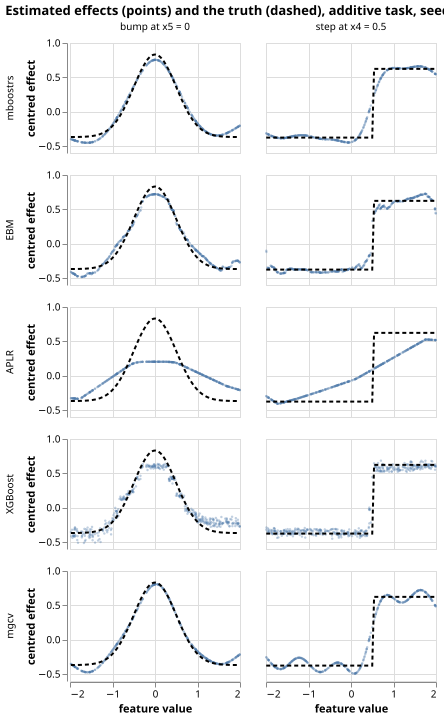

In [11]:
examples = bench["examples"]["additive"]
shown = ["mboostrs", "EBM", "APLR", "XGBoost", "mgcv"]
frames = []
for method in shown:
    ex = examples[method]
    x, est, true = (np.array(ex[k]) for k in ("x", "estimate", "truth"))
    for j, label in ((3, "step at x4 = 0.5"), (4, "bump at x5 = 0")):
        order = np.argsort(x[:, j])
        frames.append(pl.DataFrame({"x": x[order, j], "estimate": est[order, j],
                                    "truth": true[order, j], "method": method,
                                    "effect": label}))
curves = pl.concat(frames)
points = alt.Chart().mark_circle(size=6, opacity=0.35).encode(
    x=alt.X("x:Q", title="feature value"), y=alt.Y("estimate:Q", title="centred effect"))
truth = alt.Chart().mark_line(color="black", strokeDash=[4, 3]).encode(x="x:Q", y="truth:Q")
alt.layer(points, truth, data=curves).properties(width=170, height=110).facet(
    row=alt.Row("method:N", title=None, sort=shown),
    column=alt.Column("effect:N", title=None),
).properties(title="Estimated effects (points) and the truth (dashed), additive task, seed 0")

## Feature selection

Five of the ten features are pure noise. The table above counts how many of
them each method keeps by its own rule: a learner selected at the tuned step
count for mboostrs, a smooth term with $p < 0.05$ for mgcv, any split for the
tree libraries, any term for EBM and APLR (which fit every feature). It also
gives the spread of the noise features' estimated effects relative to the
signal features'.

In [12]:
noise_mb = value(insight, "mboostrs", "noise_used")
noise_desel = value(insight, "mboostrs + deselection", "noise_used")
noise_probe = value(insight, "mboostrs + probing", "noise_used")
noise_mgcv = value(insight, "mgcv", "noise_used")
bin_noise_mb = value(binary_insight, "mboostrs", "noise_used")
bin_noise_desel = value(binary_insight, "mboostrs + deselection", "noise_used")

A `gamboost` tuned by cross-validation keeps {eval}`round(noise_mb, 1)` of the
5 noise features on average: the step count that predicts best is later than
the one that selects well, and each noise term picks up a small share of the
fit. mgcv's double penalty keeps {eval}`round(noise_mgcv, 1)`. Deselection
(Strömer et al., 2022), `mb.deselect`, drops the learners whose share of
the risk reduction is under 1% and refits: it keeps
{eval}`round(noise_desel, 1)` noise features on the additive task and
{eval}`round(bin_noise_desel, 1)` on the binary task (from
{eval}`round(bin_noise_mb, 1)`), and it keeps all five signal features in
every seed. Probing (Thomas et al., 2017), `mb.probe`, stops at the first
permuted copy of a feature and keeps {eval}`round(noise_probe, 1)`. EBM and
APLR keep every feature by design; their noise terms have small effects, and
the tree libraries split on almost every feature. Importance rankings put
the five signal features first for every method, so the difference is in the
set a method reports as relevant, not in the ordering.

## Interval coverage

Four methods give a pointwise interval for an effect: mboostrs
`confint` (a bootstrap with `B_mstop=5` re-tuning each replicate), mboostrs
`gam_refit` after deselection (Bayesian intervals from the REML refit's
coefficient covariance), EBM (plus or minus 1.645 standard deviations across
its outer bags) and mgcv (its Bayesian intervals from the term standard
errors). Coverage is the share of
test rows at which the nominal 90% interval contains the true centred
effect, over the five signal features.

In [13]:
bands = (summarise(sim.filter((pl.col("scenario") == "additive")
                              & pl.col("coverage").is_not_null()),
                   ["coverage", "band_width"])
         .select("method", pl.col("coverage").alias("coverage (nominal 0.90)"),
                 pl.col("coverage se").alias("se"), pl.col("band_width").alias("mean width"))
         .sort("coverage (nominal 0.90)", descending=True))
display(annotated(
    bands,
    title="Pointwise 90% intervals for the effects, additive task",
    subtitle="Share of the true effect inside the interval, mean over 10 seeds",
    labels={"coverage (nominal 0.90)": "coverage", "mean width": "width"},
    notes=["coverage: share of the 300 evaluation points, over the five true effects, "
           "at which the interval contains the true centred effect; the nominal value is "
           "0.90. width: mean width of the interval in response units. se: standard "
           "error over seeds. No value is marked best: a coverage above 0.90 with a wider "
           "band is not better than 0.90."]))
cov_mb = value(bands, "mboostrs", "coverage (nominal 0.90)")
cov_mgcv = value(bands, "mgcv", "coverage (nominal 0.90)")
cov_ebm = value(bands, "EBM", "coverage (nominal 0.90)")
cov_refit = value(bands, "mboostrs + REML refit", "coverage (nominal 0.90)")

GT(_tbl_data=shape: (5, 4)
┌───────────────────────┬─────────────────────────┬──────────┬────────────┐
│ method                ┆ coverage (nominal 0.90) ┆ se       ┆ mean width │
│ ---                   ┆ ---                     ┆ ---      ┆ ---        │
│ str                   ┆ f64                     ┆ f64      ┆ f64        │
╞═══════════════════════╪═════════════════════════╪══════════╪════════════╡
│ mboostrs + REML refit ┆ 0.909467                ┆ 0.011539 ┆ 0.137925   │
│ mgcv                  ┆ 0.8778                  ┆ 0.012612 ┆ 0.125692   │
│ mboostrs              ┆ 0.736                   ┆ 0.018514 ┆ 0.109594   │
│ EBM                   ┆ 0.625933                ┆ 0.015517 ┆ 0.105429   │
│ EBM additive          ┆ 0.625933                ┆ 0.015517 ┆ 0.105429   │
└───────────────────────┴─────────────────────────┴──────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x11011b770>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='coverage (nominal 0.90)', type=<ColInfoTypeEnum.default: 1>, column_label='coverage', column_align='right', column_width=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None), ColInfo(var='mean width', type=<ColInfoTypeEnum.default: 1>, column_label='width', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x110202060>, _spanners=Spanners([]), _heading=Heading(title='Pointwise 90% intervals for the effects, additive task', subtitle='Share of the true effect inside the interval, mean over 10 seeds', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x110201e50>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x110200b90>, _source_notes=['coverage: share of the 300 evaluation points, over the five true effects, at which the interval contains the true centred effect; the nominal value is 0.90. width: mean width of the interval in response units. se: standard error over seeds. No value is marked best: a coverage above 0.90 with a wider band is not better than 0.90.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1102037D0>, mask=None), grpname=None, colname='coverage (nominal 0.90)', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1102037D0>, mask=None), grpname=None, colname='coverage (nominal 0.90)', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1102037D0>, mask=None), grpname=None, colname='se', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1102037D0>, mask=None), grpname=None, colname='se', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1102037D0>, mask=None), grpname=None, colname='mean width', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1102037D0>, mask=None), grpname=None, colname='mean width', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')])], _locale=<great_tables._gt_data.Locale object at 0x1102036b0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x110203410>, <great_tables._gt_data.FormatInfo object at 0x110200350>, <great_tables._gt_data.FormatInfo object at 0x110203590>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x110202cc0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=Non

mgcv's intervals cover the truth at {eval}`round(100 * cov_mgcv)`% of the
points, close to the nominal 90%. The mboostrs bootstrap covers
{eval}`round(100 * cov_mb)`%. EBM's band, 1.645 standard deviations across its
outer bags, measures how much the bags disagree rather than being a confidence
procedure; it covers {eval}`round(100 * cov_ebm)`%. Both are centred on
estimates that early stopping or bagging shrink towards zero, and resampling
reproduces the shrinkage instead of correcting it. Refitting the
deselected terms by REML replaces the boosting shrinkage with a smoothing
penalty chosen by REML, and `gam_refit`'s intervals cover
{eval}`round(100 * cov_refit)`%. Every method returned a band for all five
signal features on every seed, so no coverage figure omits a term. Use the bootstrap band to describe the
sampling variability of the boosted estimate and the refit's band for an
interval on the effect itself, conditional on the selected terms.

## Interactions

On the interaction task the true pair is $x_1 \times x_2$. EBM and APLR
search pairs during the fit; the tree libraries fit interactions implicitly,
and their pair strength is read from TreeSHAP interaction values (CatBoost's
own interaction importance). mboostrs screens pairs on the residual of the
additive fit (`screen_interactions`), and `autospec(interactions="adopt")`
adds the pair it finds.

In [14]:
inter = sim.filter(pl.col("scenario") == "interaction")
pairs = (inter.filter(pl.col("pair_searched") == True)
         .group_by("method").agg(
             (pl.col("pair_rank") == 1).mean().alias("true pair ranked first"),
             pl.col("false_pairs").mean().alias("false pair terms kept"))
         .sort("method"))
display(annotated(
    pairs,
    title="Pair search on the interaction task",
    subtitle="Share of seeds with the true pair x1 × x2 ranked first, and false pair terms kept",
    labels={"true pair ranked first": "true pair first ↑",
            "false pair terms kept": "false pairs ↓"},
    better={"true pair ranked first": "max", "false pair terms kept": "min"}, decimals=2,
    notes=["true pair first: share of the 10 seeds in which the method's pair-strength "
           "measure ranks x1 × x2 first of the 45 pairs. false pairs: mean number of pair "
           "terms other than x1 × x2 in the final model (0 for methods that model no "
           "pair set). Bold: best in the column."]))
screened = value(interaction, "mboostrs + screened pair", "excess_mse")
autospec_inter = value(interaction, "mboostrs autospec", "excess_mse")
autospec_time = value(interaction, "mboostrs autospec", "time")
ebm_false = value(pairs, "EBM", "false pair terms kept")
aplr_false = value(pairs, "APLR", "false pair terms kept")

GT(_tbl_data=shape: (8, 3)
┌───────────────┬────────────────────────┬───────────────────────┐
│ method        ┆ true pair ranked first ┆ false pair terms kept │
│ ---           ┆ ---                    ┆ ---                   │
│ str           ┆ f64                    ┆ f64                   │
╞═══════════════╪════════════════════════╪═══════════════════════╡
│ APLR          ┆ 1.0                    ┆ 41.7                  │
│ APLR additive ┆ null                   ┆ 0.0                   │
│ CatBoost      ┆ 1.0                    ┆ null                  │
│ EBM           ┆ 1.0                    ┆ 44.0                  │
│ EBM additive  ┆ null                   ┆ 0.0                   │
│ LightGBM      ┆ 1.0                    ┆ null                  │
│ XGBoost       ┆ 1.0                    ┆ null                  │
│ mboostrs      ┆ 1.0                    ┆ null                  │
└───────────────┴────────────────────────┴───────────────────────┘, _body=<great_tables._gt_data.Body object at 0x11011b770>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='true pair ranked first', type=<ColInfoTypeEnum.default: 1>, column_label='true pair first ↑', column_align='right', column_width=None), ColInfo(var='false pair terms kept', type=<ColInfoTypeEnum.default: 1>, column_label='false pairs ↓', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10db9be90>, _spanners=Spanners([]), _heading=Heading(title='Pair search on the interaction task', subtitle='Share of seeds with the true pair x1 × x2 ranked first, and false pair terms kept', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x110201e50>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x110203da0>, _source_notes=["true pair first: share of the 10 seeds in which the method's pair-strength measure ranks x1 × x2 first of the 45 pairs. false pairs: mean number of pair terms other than x1 × x2 in the final model (0 for methods that model no pair set). Bold: best in the column."], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x110202330>, mask=None), grpname=None, colname='true pair ranked first', rownum=7, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x110202330>, mask=None), grpname=None, colname='false pair terms kept', rownum=7, colnum=None, styles=[CellStyleFill(color='#e8f0fb')])], _locale=<great_tables._gt_data.Locale object at 0x110203a10>, _formats=[<great_tables._gt_data.FormatInfo object at 0x110200b90>, <great_tables._gt_data.FormatInfo object at 0x110201a30>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x110203e00>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss

Every method that searches ranks the true pair first in every seed. They
differ in what they keep: EBM's default adds
{eval}`round(ebm_false)` pair terms besides the true one and APLR's
{eval}`round(aplr_false)`, so their fitted models carry dozens of small pair
effects to read. The mboostrs screen reports a ranking and leaves the
decision to the caller; adding the top pair as a tensor gives an excess MSE of
{eval}`round(screened, 3)`, and `autospec(budget=400, interactions="adopt")`
does the same in one call ({eval}`round(autospec_inter, 3)` in
{eval}`round(autospec_time)` seconds). The price is time: the tensor design
is built in full and cross-validated, which costs seconds where the additive
fit takes a fraction of one.

## A conditional standard deviation

The heteroscedastic task asks for a predictive distribution: a mean and a
standard deviation for each row. `gamboostLSS` fits a predictor for each
(every feature in both); NGBoost boosts both parameters of a Normal by
natural gradients; mgcv's `gaulss` fits both by penalized likelihood. The
mean-only methods are given the constant training residual standard
deviation, the usual default when no scale model exists. Scores: the mean
negative log density of the test responses (log score, lower is better), the
CRPS, the coverage of the central 90% interval, and the root mean squared
error of $\log\hat\sigma$ against the true $\log\sigma$.

In [15]:
hetero = (summarise(sim.filter(pl.col("scenario") == "heteroscedastic"),
                    ["nll", "crps", "coverage90", "log_sd_error", "time"])
          .select("method", pl.col("nll").alias("log score"), pl.col("nll se").alias("se"),
                  "crps", pl.col("coverage90").alias("90% coverage"),
                  pl.col("log_sd_error").alias("log sd error"), pl.col("time").alias("seconds"))
          .sort("log score"))
display(annotated(
    hetero,
    title="Predictive distribution on the heteroscedastic task",
    subtitle="Mean over 10 seeds; the noise sd depends on x1 and x4",
    labels={"log score": "log score ↓", "crps": "CRPS ↓", "90% coverage": "90% cover",
            "log sd error": "log sd error ↓", "seconds": "s"},
    better={"log score": "min", "crps": "min", "log sd error": "min"},
    formats={"seconds": 1},
    notes=["log score: mean negative log density of the test responses under the "
           "predicted normal distribution. CRPS: continuous ranked probability score, in "
           "response units. 90% cover: share of test responses inside the central 90% "
           "predictive interval (nominal 0.90). log sd error: root mean squared error of "
           "the predicted log standard deviation against the true one. se: standard error "
           "of the log score over seeds. \"(constant sd)\": a mean model with one "
           "residual sd for every row. Bold: best in the column."]))
lss_nll = value(hetero, "mboostrs LSS", "log score")
gaulss_nll = value(hetero, "mgcv gaulss", "log score")
ngb_nll = value(hetero, "NGBoost", "log score")
lss_time = value(hetero, "mboostrs LSS", "seconds")

GT(_tbl_data=shape: (6, 7)
┌──────────────────────┬───────────┬──────────┬──────────┬──────────────┬──────────────┬───────────┐
│ method               ┆ log score ┆ se       ┆ crps     ┆ 90% coverage ┆ log sd error ┆ seconds   │
│ ---                  ┆ ---       ┆ ---      ┆ ---      ┆ ---          ┆ ---          ┆ ---       │
│ str                  ┆ f64       ┆ f64      ┆ f64      ┆ f64          ┆ f64          ┆ f64       │
╞══════════════════════╪═══════════╪══════════╪══════════╪══════════════╪══════════════╪═══════════╡
│ mgcv gaulss          ┆ 0.786115  ┆ 0.002171 ┆ 0.338579 ┆ 0.88282      ┆ 0.096768     ┆ 33.0203   │
│ mboostrs LSS         ┆ 0.786628  ┆ 0.001661 ┆ 0.339556 ┆ 0.8832       ┆ 0.092518     ┆ 1.07088   │
│ NGBoost              ┆ 0.984093  ┆ 0.006707 ┆ 0.381509 ┆ 0.86106      ┆ 0.33236      ┆ 2.385636  │
│ mboostrs (constant   ┆ 1.031543  ┆ 0.002234 ┆ 0.362964 ┆ 0.89932      ┆ 0.588327     ┆ 0.191694  │
│ sd)                  ┆           ┆          ┆          ┆              ┆              ┆           │
│ EBM (constant sd)    ┆ 1.064503  ┆ 0.005449 ┆ 0.368598 ┆ 0.87788      ┆ 0.561356     ┆ 36.887716 │
│ XGBoost (constant    ┆ 1.099488  ┆ 0.021499 ┆ 0.377132 ┆ 0.86964      ┆ 0.564484     ┆ 0.584411  │
│ sd)                  ┆           ┆          ┆          ┆              ┆              ┆           │
└──────────────────────┴───────────┴──────────┴──────────┴──────────────┴──────────────┴───────────┘, _body=<great_tables._gt_data.Body object at 0x11011b770>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='log score', type=<ColInfoTypeEnum.default: 1>, column_label='log score ↓', column_align='right', column_width=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None), ColInfo(var='crps', type=<ColInfoTypeEnum.default: 1>, column_label='CRPS ↓', column_align='right', column_width=None), ColInfo(var='90% coverage', type=<ColInfoTypeEnum.default: 1>, column_label='90% cover', column_align='right', column_width=None), ColInfo(var='log sd error', type=<ColInfoTypeEnum.default: 1>, column_label='log sd error ↓', column_align='right', column_width=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='s', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x110154950>, _spanners=Spanners([]), _heading=Heading(title='Predictive distribution on the heteroscedastic task', subtitle='Mean over 10 seeds; the noise sd depends on x1 and x4', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x110157cb0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10db9b7d0>, _source_notes=['log score: mean negative log density of the test responses under the predicted normal distribution. CRPS: continuous ranked probability score, in response units. 90% cover: share of test responses inside the central 90% predictive interval (nominal 0.90). log sd error: root mean squared error of the predicted log standard deviation against the true one. se: standard error of the log score over seeds. "(constant sd)": a mean model with one residual sd for every row. Bold: best in the column.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10EB16B70>, mask=None), grpname=None, colname='log score', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10EB16B70>, mask=None), grpname=None, colname='log score', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10EB16B70>, mask=None), grpname=None, colname='se', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=

In [16]:
gaulss_time = value(hetero, "mgcv gaulss", "seconds")
ngb_sd = value(hetero, "NGBoost", "log sd error")
lss_sd = value(hetero, "mboostrs LSS", "log sd error")

`gamboostLSS` and mgcv's `gaulss` reach the same log score
({eval}`round(lss_nll, 3)` and {eval}`round(gaulss_nll, 3)`), and both recover
the standard deviation function (error in $\log\sigma$
{eval}`round(lss_sd, 3)` for `gamboostLSS`); `gamboostLSS` takes
{eval}`round(lss_time, 1)` seconds against {eval}`round(gaulss_time, 1)`.
NGBoost's log score is {eval}`round(ngb_nll, 3)` and its $\log\sigma$ error
{eval}`round(ngb_sd, 3)`: its trees of depth 3 approximate smooth mean and
scale functions less well at 1,000 rows. The constant-variance fits show
what ignoring the scale costs: their 90% intervals still cover about 90% of
the rows on average, while their log scores are the worst in the table,
because the interval is too wide where $\sigma$ is small and too narrow
where it is large.

## Many features, few rows

`benches/bench_wide.py` repeats the additive task with 50 features, of which
the same five carry the signal, and 500 training rows. Component-wise
boosting adds one term per step, so this task examines its behaviour with many noise candidates; a
penalized-likelihood GAM estimates every smooth at once.

In [17]:
wide_bench = json.loads(Path("bench_wide.json").read_text())
wide = pl.DataFrame([r for r in wide_bench["results"] if "error" not in r])
wide_failed = pl.DataFrame([{"method": r["method"], "seed": r["seed"]}
                            for r in wide_bench["results"] if "error" in r]
                           or [{"method": "", "seed": -1}]).filter(pl.col("seed") >= 0)
wide_table = (summarise(wide, ["excess_mse", "signal_kept", "noise_kept", "top5_recall", "time"])
              .select("method", pl.col("excess_mse").alias("excess MSE"),
                      pl.col("excess_mse se").alias("se"),
                      pl.col("signal_kept").alias("signal kept (of 5)"),
                      pl.col("noise_kept").alias("noise kept (of 45)"),
                      pl.col("top5_recall").alias("top-5 recall"), pl.col("time").alias("seconds"))
              .sort("excess MSE"))

In [18]:
display(annotated(
    wide_table,
    title="Fifty features, five of them true, 500 training rows",
    subtitle="Mean over 10 seeds",
    labels={"excess MSE": "excess MSE ↓", "signal kept (of 5)": "true kept ↑",
            "noise kept (of 45)": "noise kept ↓", "top-5 recall": "top-5 recall ↑",
            "seconds": "s"},
    better={"excess MSE": "min", "signal kept (of 5)": "max", "noise kept (of 45)": "min",
            "top-5 recall": "max"},
    formats={"seconds": 1},
    notes=[EXCESS_NOTE, "true kept: true features (of 5) the method uses; noise kept: noise "
           "features (of 45) it uses. top-5 recall: share of the true features among the "
           "five the method ranks most important. se: standard error of the excess MSE. "
           "Bold: best in the column."]))
wide_best = wide_table["method"][0]
wide_desel_noise = value(wide_table, "mboostrs + deselection", "noise kept (of 45)")
wide_mb_noise = value(wide_table, "mboostrs", "noise kept (of 45)")
wide_mgcv_noise = value(wide_table, "mgcv", "noise kept (of 45)")
wide_mgcv_time = value(wide_table, "mgcv", "seconds")
wide_desel_time = value(wide_table, "mboostrs + deselection", "seconds")

GT(_tbl_data=shape: (8, 7)
┌───────────────┬────────────┬──────────┬───────────────┬──────────────┬──────────────┬────────────┐
│ method        ┆ excess MSE ┆ se       ┆ signal kept   ┆ noise kept   ┆ top-5 recall ┆ seconds    │
│ ---           ┆ ---        ┆ ---      ┆ (of 5)        ┆ (of 45)      ┆ ---          ┆ ---        │
│ str           ┆ f64        ┆ f64      ┆ ---           ┆ ---          ┆ f64          ┆ f64        │
│               ┆            ┆          ┆ f64           ┆ f64          ┆              ┆            │
╞═══════════════╪════════════╪══════════╪═══════════════╪══════════════╪══════════════╪════════════╡
│ mboostrs +    ┆ 0.028379   ┆ 0.001204 ┆ 5.0           ┆ 0.0          ┆ 1.0          ┆ 4.126053   │
│ deselection   ┆            ┆          ┆               ┆              ┆              ┆            │
│ mboostrs +    ┆ 0.031222   ┆ 0.002437 ┆ 5.0           ┆ 0.4          ┆ 1.0          ┆ 1.76047    │
│ probing       ┆            ┆          ┆               ┆              ┆              ┆            │
│ mgcv          ┆ 0.040481   ┆ 0.002352 ┆ 5.0           ┆ 4.1          ┆ 1.0          ┆ 1114.218   │
│ mboostrs      ┆ 0.059024   ┆ 0.003288 ┆ 5.0           ┆ 19.8         ┆ 1.0          ┆ 6.169224   │
│ LightGBM      ┆ 0.09042    ┆ 0.004065 ┆ 5.0           ┆ 35.2         ┆ 1.0          ┆ 2.093592   │
│ XGBoost       ┆ 0.095318   ┆ 0.004976 ┆ 5.0           ┆ 34.2         ┆ 1.0          ┆ 6.710509   │
│ APLR          ┆ 0.171103   ┆ 0.005367 ┆ 5.0           ┆ 38.6         ┆ 1.0          ┆ 6.9479     │
│ EBM           ┆ 0.20669    ┆ 0.006515 ┆ 5.0           ┆ 45.0         ┆ 1.0          ┆ 494.272169 │
└───────────────┴────────────┴──────────┴───────────────┴──────────────┴──────────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x110190e30>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='excess MSE', type=<ColInfoTypeEnum.default: 1>, column_label='excess MSE ↓', column_align='right', column_width=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='se', column_align='right', column_width=None), ColInfo(var='signal kept (of 5)', type=<ColInfoTypeEnum.default: 1>, column_label='true kept ↑', column_align='right', column_width=None), ColInfo(var='noise kept (of 45)', type=<ColInfoTypeEnum.default: 1>, column_label='noise kept ↓', column_align='right', column_width=None), ColInfo(var='top-5 recall', type=<ColInfoTypeEnum.default: 1>, column_label='top-5 recall ↑', column_align='right', column_width=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='s', column_align='right', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x1143740b0>, _spanners=Spanners([]), _heading=Heading(title='Fifty features, five of them true, 500 training rows', subtitle='Mean over 10 seeds', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10db9be90>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10db9b800>, _source_notes=['excess MSE: held-out mean squared error minus that of the true mean function on the same test rows, in squared response units; 0 is a perfect estimate of the mean (on one test set it can be slightly negative).', 'true kept: true features (of 5) the method uses; noise kept: noise features (of 45) it uses. top-5 recall: share of the true features among the five the method ranks most important. se: standard error of the excess MSE. Bold: best in the column.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x114375160>, mask=None), grpname=None, colname='excess MSE', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x114375160>, mask=None), grpname=None, colname='excess MSE', rownum=1, colnum=None, style

With 45 noise candidates the lowest excess MSE is {eval}`wide_best`'s. The
CV-tuned `gamboost` keeps {eval}`round(wide_mb_noise, 1)` of the 45 noise
features; after deselection it keeps {eval}`round(wide_desel_noise, 1)`.
mgcv keeps {eval}`round(wide_mgcv_noise, 1)` noise features and takes
{eval}`round(wide_mgcv_time)` seconds per fit, against
{eval}`round(wide_desel_time, 1)` for deselection.

## Real data: accuracy, speed and stability

Four real data sets, each split 5 times at random into 75% training and 25%
test rows: diabetes (442 rows, 10 features), a 5,000-row sample of California
housing (8 features), breast cancer (569 rows, 30 features) and credit-g
(1,000 rows, 48 columns after indicator coding). mboostrs and mgcv use a
smooth term for a column with more than five distinct values and a linear
term otherwise. Every method completes all five splits of every data set.
`autospec` chooses the response family itself. When it adopts a
distributional model (`LSSModel`, a location, scale and shape model in which each parameter has its own additive predictor), the fit is scored on the mean parameter
`mu` on the response scale, the quantity the other methods' $R^2$ measures,
and its feature contributions and term counts come from the `mu` model. On
diabetes it compares a count family with a Gaussian one on held-out folds
before keeping it. Stability is the mean Jaccard overlap (the share of features that two sets have in common) of the five most
important features (largest contribution spread) between pairs of splits: 1
means every split names the same five features.

In [19]:
real = results.filter(pl.col("dataset").is_not_null())
real = real.with_columns(pl.coalesce("r2", "auc").alias("score"))


def jaccard(tops):
    sets = [set(t) for t in tops]
    pairs = [(a, b) for i, a in enumerate(sets) for b in sets[i + 1:]]
    return float(np.mean([len(a & b) / len(a | b) for a, b in pairs])) if pairs else float("nan")


# One Jaccard mean per data set and method, over that method's splits.
stability = pl.DataFrame(
    [{"dataset": d, "method": m, "top-5 stability": jaccard(tops.to_list())}
     for (d, m), tops in ((key, group["top5"])
                          for key, group in real.group_by("dataset", "method"))],
    schema={"dataset": pl.String, "method": pl.String, "top-5 stability": pl.Float64})
real_table = (real.group_by("dataset", "method")
              .agg(pl.col("score").mean(),
                   pl.col("time").mean().alias("seconds"),
                   pl.col("n_used").mean().alias("features used"))
              .join(stability, on=["dataset", "method"])
              .sort("dataset", "score", descending=[False, True]))
real_label = {"diabetes": "diabetes (R²)", "california": "california (R²)",
              "breast_cancer": "breast cancer (AUC)", "credit_g": "credit-g (AUC)"}

In [20]:
display(annotated(
    real_table.with_columns(pl.col("dataset").replace(real_label).alias("data")).drop("dataset"),
    title="Four real data sets: accuracy, time and stability",
    subtitle="Mean over 5 random 75/25 splits",
    group="data",
    labels={"score": "score ↑", "seconds": "s", "features used": "features",
            "top-5 stability": "top-5 stability ↑"},
    better={"score": "max", "top-5 stability": "max"},
    formats={"seconds": 1, "features used": 1},
    notes=["score: test R² for the two regression data sets, test AUC for the two binary "
           "ones. features: features the fitted model uses. top-5 stability: mean Jaccard "
           "overlap between the five most important features of each pair of splits "
           "(1 means the same five every time). s: mean seconds per fit including tuning. "
           "Bold: best within each data set."]))

GT(_tbl_data=shape: (32, 6)
┌───────────────────┬──────────┬───────────┬───────────────┬─────────────────┬─────────────────────┐
│ method            ┆ score    ┆ seconds   ┆ features used ┆ top-5 stability ┆ data                │
│ ---               ┆ ---      ┆ ---       ┆ ---           ┆ ---             ┆ ---                 │
│ str               ┆ f64      ┆ f64       ┆ f64           ┆ f64             ┆ str                 │
╞═══════════════════╪══════════╪═══════════╪═══════════════╪═════════════════╪═════════════════════╡
│ EBM               ┆ 0.996816 ┆ 52.273404 ┆ 30.0          ┆ 0.440476        ┆ breast cancer (AUC) │
│ mboostrs          ┆ 0.995953 ┆ 1.645557  ┆ 16.0          ┆ 0.440476        ┆ breast cancer (AUC) │
│ LightGBM          ┆ 0.995415 ┆ 0.334142  ┆ 22.6          ┆ 0.557143        ┆ breast cancer (AUC) │
│ XGBoost           ┆ 0.995088 ┆ 0.871718  ┆ 24.2          ┆ 0.363095        ┆ breast cancer (AUC) │
│ CatBoost          ┆ 0.99488  ┆ 5.855611  ┆ 29.0          ┆ 0.482143        ┆ breast cancer (AUC) │
│ …                 ┆ …        ┆ …         ┆ …             ┆ …               ┆ …                   │
│ APLR              ┆ 0.450166 ┆ 0.559409  ┆ 8.8           ┆ 0.67619         ┆ diabetes (R²)       │
│ mboostrs autospec ┆ 0.44202  ┆ 5.504033  ┆ 6.6           ┆ 0.590476        ┆ diabetes (R²)       │
│ CatBoost          ┆ 0.441712 ┆ 0.340306  ┆ 9.8           ┆ 0.652381        ┆ diabetes (R²)       │
│ LightGBM          ┆ 0.413825 ┆ 0.058846  ┆ 7.8           ┆ 0.866667        ┆ diabetes (R²)       │
│ XGBoost           ┆ 0.401066 ┆ 0.15202   ┆ 8.8           ┆ 0.742857        ┆ diabetes (R²)       │
└───────────────────┴──────────┴───────────┴───────────────┴─────────────────┴─────────────────────┘, _body=<great_tables._gt_data.Body object at 0x110202ed0>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None), ColInfo(var='score', type=<ColInfoTypeEnum.default: 1>, column_label='score ↑', column_align='right', column_width=None), ColInfo(var='seconds', type=<ColInfoTypeEnum.default: 1>, column_label='s', column_align='right', column_width=None), ColInfo(var='features used', type=<ColInfoTypeEnum.default: 1>, column_label='features', column_align='right', column_width=None), ColInfo(var='top-5 stability', type=<ColInfoTypeEnum.default: 1>, column_label='top-5 stability ↑', column_align='right', column_width=None), ColInfo(var='data', type=<ColInfoTypeEnum.row_group: 3>, column_label='data', column_align='left', column_width=None)]), _stub=<great_tables._gt_data.Stub object at 0x10eb166c0>, _spanners=Spanners([]), _heading=Heading(title='Four real data sets: accuracy, time and stability', subtitle='Mean over 5 random 75/25 splits', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x110201e50>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10db9b7d0>, _source_notes=['score: test R² for the two regression data sets, test AUC for the two binary ones. features: features the fitted model uses. top-5 stability: mean Jaccard overlap between the five most important features of each pair of splits (1 means the same five every time). s: mean seconds per fit including tuning. Bold: best within each data set.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1142A36B0>, mask=None), grpname=None, colname='score', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1142A36B0>, mask=None), grpname=None, colname='score', rownum=6, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x1142A36B0>, mask=None), grpname=None, colname='score', rownum=13, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname

In [21]:
# Summarize the recorded California results separately for the GAM and LSS fits.
def real_value(dataset, method, column="score"):
    return real_table.filter((pl.col("dataset") == dataset) & (pl.col("method") == method))[column][0]


cal_mb = real_value("california", "mboostrs")
cal_best = real_table.filter(pl.col("dataset") == "california")["score"].max()
cal_mgcv = real_value("california", "mgcv")
cal_autospec = real_value("california", "mboostrs autospec")
cal_rows = real.filter((pl.col("dataset") == "california")
                       & (pl.col("method") == "mboostrs autospec"))
cal_lss = cal_rows.filter(pl.col("model_class") == "LSSModel")
cal_gam = cal_rows.filter(pl.col("model_class") != "LSSModel")
def _list_and(items):
    items = [str(i) for i in items]
    return items[0] if len(items) == 1 else ", ".join(items[:-1]) + " and " + items[-1]


cal_lss_splits = _list_and(sorted(cal_lss["split"].to_list()))
cal_lss_n = cal_lss.height
cal_lss_family = _list_and([
    f"{family} on split{'s' if len(s) > 1 else ''} {_list_and(sorted(s))}"
    for family, s in ((f, cal_lss.filter(pl.col("family") == f)["split"].to_list())
                      for f in sorted(set(cal_lss["family"].to_list())))])
cal_gam_splits = _list_and(sorted(cal_gam["split"].to_list()))
cal_lss_r2 = cal_lss["score"].mean()
cal_gam_r2 = cal_gam["score"].mean()
cal_lss_terms = cal_lss["n_used"].mean()
bc_mgcv_time = real_value("breast_cancer", "mgcv", "seconds")
credit_best_method = real_table.filter(pl.col("dataset") == "credit_g")["method"][0]

On diabetes, breast cancer and credit-g the methods finish within a few
hundredths of each other, and the ordering changes between splits; CatBoost
is ahead on credit-g ({eval}`credit_best_method` has the highest mean AUC).
California housing is the exception, and the reason is not additivity.
`gamboost` with a spline on every raw column reaches $R^2$
{eval}`round(cal_mb, 2)`, mgcv {eval}`round(cal_mgcv, 2)`, the best method
{eval}`round(cal_best, 2)`. Four of the columns are heavy-tailed (average
occupancy reaches several hundred where most rows are below 5). A P-spline's
knots are spaced evenly over the whole range, so most of the curve sits over
a handful of extreme rows; in cross-validation, a fold that holds those rows
out extends the curve across a range its training rows never covered, its
held-out risk explodes, and the tuned step count follows that fold. On one
split the search stopped at 11 of 2,000 steps although held-out $R^2$ kept
rising to 0.71 at 2,000; fitting the four columns on the log scale
(`bbs(log(x))`) gives 0.72. EBM and the tree libraries bin by quantiles and
are unaffected. `autospec` fits such a column as `bbs(log(x))` (the
"mboostrs autospec" row, mean $R^2$ {eval}`round(cal_autospec, 2)` over five splits). On
splits {eval}`cal_lss_splits` its family search adopted a distributional model
({eval}`cal_lss_family`), fitted with L2 gradient stabilization and scored on
its mean parameter `mu`. The search adopts a distributional family only when
its held-out log score beats the mean model's and the squared error of its
mean is no worse than the mean model's by more than 2% and two paired standard
errors. The search ends at that family, so the model has no shape, pair or
residual-tree terms. The {eval}`cal_lss_n` splits have a mean $R^2$ of
{eval}`round(cal_lss_r2, 2)` and use {eval}`round(cal_lss_terms)` features in the
`mu` model, against {eval}`round(cal_gam_r2, 2)` for split {eval}`cal_gam_splits`, where it kept a
single-predictor Gaussian model and its later probes added shape and pair
terms. The mean check compares the distributional model with the Gaussian
model before those probes, so it does not see their gain. `cvrisk`
warns when one fold's held-out risk is more than ten times the median
fold's. For a hand-written formula, `bbs(ecdf(x))`, which passes the column through its empirical cumulative distribution function (ecdf) before the spline, puts the spline's knots at quantiles of the training column and holds the effect flat beyond its
range, as the binning methods do; on three of these splits it reached
held-out $R^2$ 0.73 to 0.74 with a spline on every column, where raw `bbs`
reached −0.19 to 0.66 (see [](../usage/real_data.ipynb)). mgcv's time on breast cancer,
{eval}`round(bc_mgcv_time)` seconds per fit, comes from estimating 30 smooth
terms with the double penalty on 426 rows.

## Summary

| Question | Where mboostrs stands | Leader |
|---|---|---|
| Accuracy, additive structure | the plain CV fit is close to the best; `autospec` and deselection lead | mboostrs autospec, mboostrs + deselection, mgcv |
| Accuracy, interaction | additive fit cannot represent it; the screened or `autospec`-adopted pair gives the best model | mboostrs with the pair; CatBoost among the rest |
| Shape recovery | close to mgcv on smooth shapes; a spline rounds off a step, and `autospec`'s shape probe replaces it by a tree | mgcv; mboostrs autospec and trees on the step |
| Relevant-feature set | the CV fit keeps most noise features; deselection or probing removes them | mboostrs + deselection, mgcv |
| Pair discovery | the screen ranks the true pair first and proposes one term | all searchers find it; EBM and APLR keep dozens of false pairs |
| Interval coverage | the bootstrap under-covers; the REML refit (`gam_refit`) reaches the nominal level | mboostrs + REML refit, mgcv |
| Conditional standard deviation | ties mgcv's `gaulss`, far faster | mboostrs LSS, mgcv |
| Heavy-tailed predictors | a hand-written `bbs` on the raw column fails; `autospec` proposes `bbs(log(x))`, `bbs(ecdf(x))` places knots at quantiles, and `cvrisk` warns | EBM and trees; mboostrs autospec |
| Time | the fastest smooth method by one to two orders of magnitude over mgcv and EBM | LightGBM overall |

Simultaneous bands for the REML refit are not implemented; pointwise bands are the current route.

## Limitations

The simulated tasks are small (1,000 training rows, ten features) and their
effects are smooth except for one step; a benchmark built around steps and
high-order interactions would favour the tree libraries. Each method runs
with its documented defaults plus the tuning described in the method table;
none was tuned beyond that, and a specialist could do better with any of
them. Timing is single-threaded; libraries that parallelise well are
understated. The real data sets are the ones the existing library comparison
uses, so they share its limits: dense, small to medium, few categorical columns.

Missing values are not handled inside a base learner (EBM's missing bin, a tree's default direction); `na_action="impute"` is the current route.

See also [](library_comparison.ipynb) for accuracy under equal tuning effort,
[](distributional_comparison.ipynb) for predictive distributions,
[](benchmark_causal.ipynb) for treatment effects and
[](benchmark_runtime_api.ipynb) for fit time, memory and API effort.